# 06 — Barragens a jusante: Piraju e Paranapanema
> **Estudo educacional independente; não substitui o PAE oficial, a Defesa Civil ou laudo de engenharia.**

Fontes: **PAE UHE Piraju** (CBA, 3308-HID-CBA-A-RT-G00-0001), **PAE UHE Paranapanema** (Enel) e **PSB de Piraju** (resumo). Este notebook mostra como as tabelas foram lidas, como foram checadas e **o que não existe** nas fontes. **Ruptura em cascata não foi modelada**: aqui só há cenários *isolados*.

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from jurumirim import DISCLAIMER
print(DISCLAIMER)

Estudo educacional independente; não substitui o PAE oficial, a Defesa Civil ou laudo de engenharia.


## 1. Numeração de páginas
O PAE Piraju tem capa + 86 páginas numeradas: **página do PDF = impressa + 1**. O complemento do projeto cita páginas impressas. Abaixo, o rótulo 'Páginas: N de 86' lido de cada página do PDF.

In [2]:
import pymupdf
from jurumirim import cascade, paths
if paths.PIRAJU_PDF.exists():
    with pymupdf.open(paths.PIRAJU_PDF) as d:
        print([(i, cascade._printed_page(d[i-1].get_text())) for i in (3, 45, 62, 63, 64, 82)], '(pág. PDF, impressa)')
else:
    print('PDF do PAE Piraju ausente: célula ignorada (os dados processados já estão no repositório).')

[(3, 2), (45, 44), (62, 61), (63, 62), (64, 63), (82, 81)] (pág. PDF, impressa)


## 2. As Tabelas 9 e 10 são imagens
Não há texto extraível; foram lidas por **OCR** (RapidOCR, em duas escalas) a partir das imagens embutidas. O OCR é dependência *opcional* (`make ocr`); o resultado bruto fica versionado em `data/processed/dams/PIR/ocr_raw/`.

In [3]:
from jurumirim import piraju_tables as pt
D = paths.PROCESSED / 'dams' / 'PIR' / 'ocr_raw'
t10a = pt.parse_table10(pt.load(D/'tabela10_top_s1.json'), pt.load(D/'tabela10_bottom_s1.json'))
t10b = pt.parse_table10(pt.load(D/'tabela10_top_s1.5.json'), pt.load(D/'tabela10_bottom_s1.5.json'))
t9a = pt.parse_table9(pt.load(D/'tabela9_s2.json')); t9b = pt.parse_table9(pt.load(D/'tabela9_s3.json'))
print('linhas T10:', len(t10a), '| T9:', len(t9a))
print('discordâncias entre escalas — T10:', pt.crosscheck(t10a, t10b), '| T9:', pt.crosscheck(t9a, t9b))
t10a[t10a.tr_anos == 10000].head(8)

linhas T10: 46 | T9: 115
discordâncias entre escalas — T10: [] | T9: []


,secao,tr_anos,distancia_km,elev_fundo_m,prof_max_m,vel_max_ms,elev_max_m,vazao_max_m3s,t_pico_min,t_frente_min,vazao_marcada_asterisco
0,ST-00,10000,0.0,501.71,30.95,7.44,532.70,26857.0,0.0,0.0,False
1,ST-01,10000,0.0,491.62,36.04,13.02,528.81,26813.0,12.0,3.0,False
2,ST-02,10000,1.0,491.94,34.10,7.91,526.55,23621.0,19.0,4.0,False
3,ST-03,10000,2.0,491.94,30.48,10.67,522.90,22519.0,21.0,6.0,False
4,ST-04,10000,3.0,485.17,36.19,9.66,521.37,21315.0,22.0,7.0,False
5,ST-05,10000,4.0,490.08,31.20,7.21,521.46,17033.0,23.0,9.0,False
6,ST-06,10000,5.0,491.75,28.90,6.81,520.67,15886.0,26.0,11.0,False
7,ST-07,10000,6.0,490.42,30.10,4.45,520.55,13663.0,32.0,13.0,False


O parser **falha com erro** se uma linha não tiver exatamente o número esperado de campos (nada é adivinhado). Duas exceções conhecidas e tratadas: o `-` de ST-22 (tempo da onda) e as velocidades `-` de ST-00 na Tabela 9.

## 3. Checagens independentes do OCR
As duas escalas usam o mesmo motor, então concordância mostra estabilidade, não verdade. Por isso há checagens **físicas**:

In [4]:
r = t10a.copy(); r['gap'] = r.elev_max_m - r.elev_fundo_m - r.prof_max_m
n = t9a.copy(); n['gap'] = n.elev_max_m - n.elev_fundo_m - n.prof_max_m
print('cota − fundo − profundidade (m): T10', r.gap.min().round(2), '…', r.gap.max().round(2), '| T9', n.gap.min().round(2), '…', n.gap.max().round(2))
m = t10a[t10a.tr_anos==10000].merge(t9a[t9a.tr_anos==10000], on='secao', suffixes=('_rup','_nat'))
print('T9×T10 (imagens distintas) coincidem em fundo e distância:', bool((m.elev_fundo_m_rup==m.elev_fundo_m_nat).all() and (m.distancia_km_rup==m.distancia_km_nat).all()))
print('ruptura ≥ cheia natural (cota máx., TR 10.000):', bool((m.elev_max_m_rup >= m.elev_max_m_nat).all()))
for tr, g in t10a.groupby('tr_anos'):
    g = g.sort_values('secao'); print(f'TR {tr}: distância e tempo de chegada crescentes:', g.distancia_km.is_monotonic_increasing, g.t_frente_min.dropna().is_monotonic_increasing)

cota − fundo − profundidade (m): T10 0.0 … 1.15 | T9 -0.01 … 1.37
T9×T10 (imagens distintas) coincidem em fundo e distância: True
ruptura ≥ cheia natural (cota máx., TR 10.000): True
TR 10: distância e tempo de chegada crescentes: True True
TR 10000: distância e tempo de chegada crescentes: True True


Uma ressalva importante: **os dois motores/leituras podem errar do mesmo jeito** e não houve revisão de engenheiro. Se você for citar um número, confira na página impressa 62 (Tabela 10) do PAE.

## 4. Posição das seções de Piraju (ILUSTRAÇÃO)
O PDF não traz coordenadas das seções. A Figura 17 (raster) tem grade UTM e rótulos ST-xx. Usamos **a distância do PAE ao longo do rio** para posicionar cada seção sobre o eixo do Rio Paranapanema (OSM) e validamos contra documentos independentes:

In [5]:
from jurumirim import dams as DM
v = DM.validation()
for k in ['fig17_rms_m','fig17_n_control_points','fig17_pixel_size_m','km_osm_piraju_to_paranapanema_dam','km_pae_piraju_zas','pos_9_68km_to_official_paranapanema_dam_m','piraju_official_vs_jurumirim_st017_m','label_offset_m_min','label_offset_m_max']:
    print(f'{k:48s}', v[k])
print(v['nota'])

fig17_rms_m                                      7.04
fig17_n_control_points                           14
fig17_pixel_size_m                               18.18
km_osm_piraju_to_paranapanema_dam                9.73
km_pae_piraju_zas                                9.68
pos_9_68km_to_official_paranapanema_dam_m        46
piraju_official_vs_jurumirim_st017_m             45
label_offset_m_min                               445
label_offset_m_max                               1070
Posições das seções de Piraju por quilometragem sobre o eixo OSM: ILUSTRAÇÃO (±centenas de m). Distâncias a rótulos da Fig.17 só limitam grosseiramente (caixas de texto ficam ao lado das linhas).


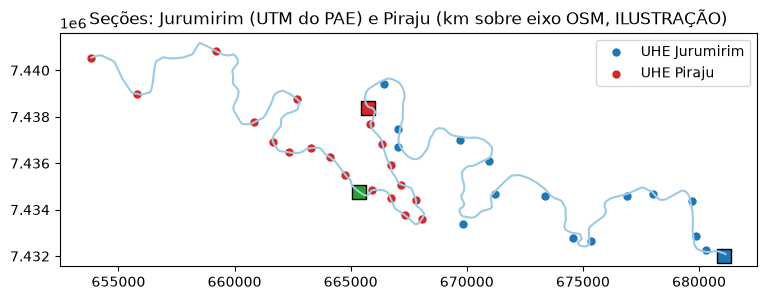

In [6]:
import matplotlib.pyplot as plt
from jurumirim import selection as S
sel = S.make(S.MODE_TODAS, ['JUR','PIR','PAR'])
s = S.sections_for(sel); rx, ry = DM.river_xy(); dp = DM.dam_points().set_index('dam')
fig, ax = plt.subplots(figsize=(9, 5)); ax.plot(rx, ry, color='#9ecae1')
for dam, g in s.groupby('dam'): ax.scatter(g.x_utm, g.y_utm, c=DM.COLORS[dam], s=25, label=DM.DAMS[dam].name)
for dam in dp.index: ax.scatter(dp.loc[dam,'x_utm'], dp.loc[dam,'y_utm'], marker='s', s=90, c=DM.COLORS[dam], ec='k')
ax.set_aspect('equal'); ax.legend(); ax.set_title('Seções: Jurumirim (UTM do PAE) e Piraju (km sobre eixo OSM, ILUSTRAÇÃO)'); plt.show()

Duas coisas **não existem** nos PDFs: a **mancha georreferenciada** de Piraju (Apêndice 9 só lista os arquivos) e os **mapas/tempos** da Paranapanema (Figuras 2–6 são capturas do HEC-RAS sem coordenadas). Nada foi desenhado por suposição.

## 5. O filtro: 'Por Barragem Isolada' × 'Todas barragens selecionadas'
'Todas' **sobrepõe cenários isolados**; cada um usa o **relógio da própria ruptura**. Provamos que Piraju não depende de Jurumirim estar selecionada:

In [7]:
t = 30
alone = S.state_at(S.make(S.MODE_ISOLADA, ['PIR']), t).reset_index(drop=True)
both = S.state_at(S.make(S.MODE_TODAS, ['JUR','PIR']), t); both = both[both.dam=='PIR'].reset_index(drop=True)
print('Estado de Piraju em t=30 min idêntico com/sem Jurumirim:', alone.equals(both))
S.summary_at(S.make(S.MODE_TODAS, ['JUR','PIR','PAR']), 60)

Estado de Piraju em t=30 min idêntico com/sem Jurumirim: True


,barragem,cenario,secoes_atingidas,ate_km,ultima_secao,vazao_pico_ultima_m3s
0,UHE Jurumirim,"Ruptura isolada em dia seco, N.A. 568,00 m",9 de 17,13.69,ST-009,20304.0
1,UHE Piraju,"Ruptura isolada, TR 10.000 anos (N.A. inicial ...",21 de 23,24.50,ST-20,14005.0
2,UHE Paranapanema,—,sem tabela de seções no PAE,NaN,—,NaN


## 6. Inconsistências nas próprias fontes
Registradas como publicadas; não foram corrigidas nem usadas em cálculos.

In [8]:
f = DM.facts(); f[f.flag.notna()][['dam','label','value','unit','page_printed','page_pdf','note']]

,dam,label,value,unit,page_printed,page_pdf,note
14,PAR,Área inundada no N.A. máximo normal,1.71,km²,5.0,5,"Ficha informa 18,24 km² no N.A. máx. maximorum..."
15,PAR,Área inundada no N.A. máximo maximorum,18.24,km²,5.0,5,NaN
35,PIR,Vertedouro controlado: capacidade máxima no N....,2621,m³/s (aprox.),11.0,12,Quadro 1 (p.14 impressa) informa vazão de proj...
36,PIR,Vertedouro controlado: vazão de projeto (Quadr...,2594.0,m³/s,14.0,15,Texto da p.11 informa ≈2.621 m³/s.
50,PIR,"Vazão natural sem ruptura, TR 10.000 anos (Qua...",2827.2,m³/s,59.0,60,Tabela 8 (p.44 impressa) informa 2.829 m³/s pa...
51,PIR,"Tabela 9, ST-00 (reservatório): cota máx. para...",532.7,m,61.0,62,"É maior que a de TR 50 anos (531,50 m) e difer..."


## Limites
- Sem hidrograma completo, sem mancha de Piraju/Paranapanema, sem estudo de cascata.
- Pico de vazão não é hidrograma; comparar picos de estudos diferentes **não** prova falha nem segurança.
- O PSB de Piraju traz 'Sigilo: Interno': confirme a possibilidade de divulgação antes de publicar derivados.